# Serving and Systems Tradeoffs: Theory Notebook

This notebook makes serving tradeoffs concrete: Little's law, queue utilization, latency budgets, batching, KV memory, cost per token, autoscaling, and SLO budgets.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Little's law

In [2]:
arrival_rate = 20  # requests/sec
avg_latency = 1.5  # sec
concurrency = arrival_rate * avg_latency
print("average concurrency:", concurrency)

average concurrency: 30.0


## 2. Utilization and queueing delay intuition

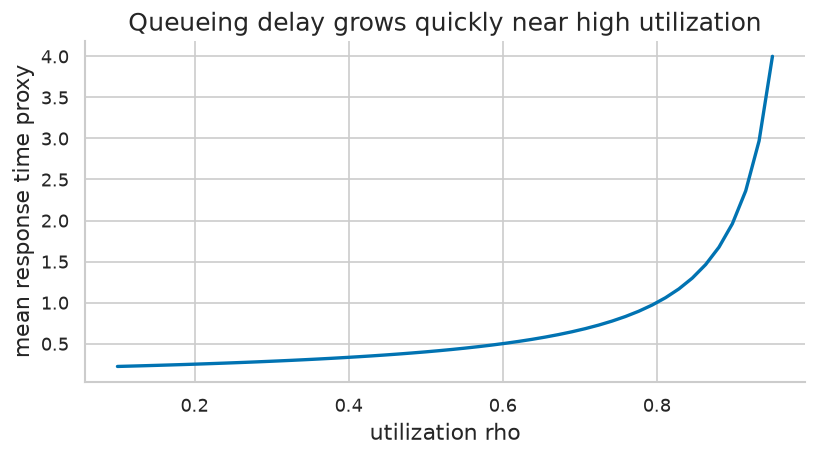

latency at rho=0.8: 1.0000000000000002


In [3]:
rho = np.linspace(0.1, 0.95, 50)
service_time = 0.2
mm1_latency = service_time / (1 - rho)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rho, mm1_latency)
ax.set_title("Queueing delay grows quickly near high utilization")
ax.set_xlabel("utilization rho")
ax.set_ylabel("mean response time proxy")
fig.tight_layout()
plt.show()
print("latency at rho=0.8:", service_time / (1 - 0.8))

## 3. Latency budget

In [4]:
queue_ms = 30
prefill_ms = 250
output_tokens = 80
tpot_ms = 25
post_ms = 15
ttft = queue_ms + prefill_ms
total = ttft + output_tokens * tpot_ms + post_ms
print("TTFT ms:", ttft)
print("total latency ms:", total)

TTFT ms: 280
total latency ms: 2295


## 4. Batch throughput versus latency

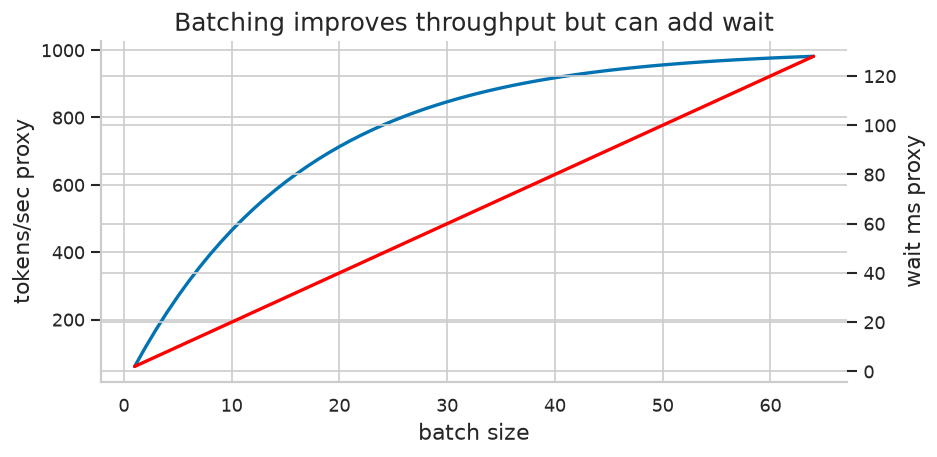

batch 32 throughput proxy: 864.6647167633873 wait proxy: 64.0


In [5]:
batch = np.arange(1, 65)
throughput = 1000 * (1 - np.exp(-batch / 16))
queue_wait = 2.0 * batch
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(batch, throughput, label="throughput proxy")
ax1.set_xlabel("batch size")
ax1.set_ylabel("tokens/sec proxy")
ax2 = ax1.twinx()
ax2.plot(batch, queue_wait, color="red", label="queue wait proxy")
ax2.set_ylabel("wait ms proxy")
ax1.set_title("Batching improves throughput but can add wait")
fig.tight_layout()
plt.show()
print("batch 32 throughput proxy:", throughput[31], "wait proxy:", queue_wait[31])

## 5. Max concurrency from KV memory

In [6]:
gpu_gb = 80
weights_gb = 28
workspace_gb = 8
available_kv = gpu_gb - weights_gb - workspace_gb
kv_per_request_gb = 0.55
max_requests = int(available_kv // kv_per_request_gb)
print("available KV GB:", available_kv)
print("max concurrent requests:", max_requests)

available KV GB: 44
max concurrent requests: 79


## 6. Cost per million tokens

In [7]:
gpu_hour_cost = 4.0
tokens_per_sec = 1200
cpm = 1e6 * gpu_hour_cost / (3600 * tokens_per_sec)
print("cost per million tokens:", cpm)

cost per million tokens: 0.9259259259259259


## 7. Utilization-adjusted cost

In [8]:
nominal_cpm = cpm
for util in [0.3, 0.5, 0.7, 0.9]:
    print(f"util={util:.1f}: effective CPM={nominal_cpm / util:.3f}")

util=0.3: effective CPM=3.086
util=0.5: effective CPM=1.852
util=0.7: effective CPM=1.323
util=0.9: effective CPM=1.029


## 8. Autoscaling replica count

In [9]:
arrival_rate = 180
service_rate_per_replica = 40
target_util = 0.70
replicas = int(np.ceil(arrival_rate / (target_util * service_rate_per_replica)))
print("needed replicas:", replicas)
print("resulting utilization:", arrival_rate / (replicas * service_rate_per_replica))

needed replicas: 7
resulting utilization: 0.6428571428571429


## 9. Error budget

In [10]:
requests = 2_000_000
slo = 0.995
allowed_bad = int((1 - slo) * requests)
print("allowed bad requests per window:", allowed_bad)

allowed bad requests per window: 10000


## 10. Tail latency from samples

In [11]:
rng = np.random.default_rng(9)
latency = rng.lognormal(mean=np.log(800), sigma=0.45, size=5000)
for p in [50, 90, 95, 99]:
    print(f"p{p} latency ms:", np.percentile(latency, p))

p50 latency ms: 807.1134913904799
p90 latency ms: 1437.6170471916005
p95 latency ms: 1688.5727007095686
p99 latency ms: 2232.653336091306


## 11. Graceful degradation choice

In [12]:
actions = [
    {"name": "keep full", "latency": 2500, "quality": 1.00},
    {"name": "smaller model", "latency": 900, "quality": 0.92},
    {"name": "shorter answer", "latency": 1200, "quality": 0.95},
    {"name": "lower retrieval k", "latency": 1500, "quality": 0.97},
]
slo_ms = 1600
eligible = [a for a in actions if a["latency"] <= slo_ms]
best = max(eligible, key=lambda a: a["quality"])
print("best eligible action:", best)

best eligible action: {'name': 'lower retrieval k', 'latency': 1500, 'quality': 0.97}


## 12. Serving trace checklist

In [13]:
checks = [
    "arrival time, queue time, and scheduler decision",
    "prompt tokens, output tokens, TTFT, and TPOT",
    "prefill time and decode time separately",
    "KV cache memory and batch size over time",
    "model version, quantization format, and fallback path",
    "status, error type, and user-visible latency",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. arrival time, queue time, and scheduler decision
2. prompt tokens, output tokens, TTFT, and TPOT
3. prefill time and decode time separately
4. KV cache memory and batch size over time
5. model version, quantization format, and fallback path
6. status, error type, and user-visible latency


## New demo: M/M/1 queue blow-up (new, notes 12)

In [14]:
mu=10.0
for lam in [5,8,9,9.5]:
    print(f"lambda={lam}: util={lam/mu:.0%} mean system={1/(mu-lam):.2f}s")
print(f"{'PASS' if abs(1/(mu-9)-1.0)<1e-9 else 'FAIL'} - queue arithmetic")

lambda=5: util=50% mean system=0.20s
lambda=8: util=80% mean system=0.50s
lambda=9: util=90% mean system=1.00s
lambda=9.5: util=95% mean system=2.00s
PASS - queue arithmetic


## New demo: Queue plot (new, notes 12)

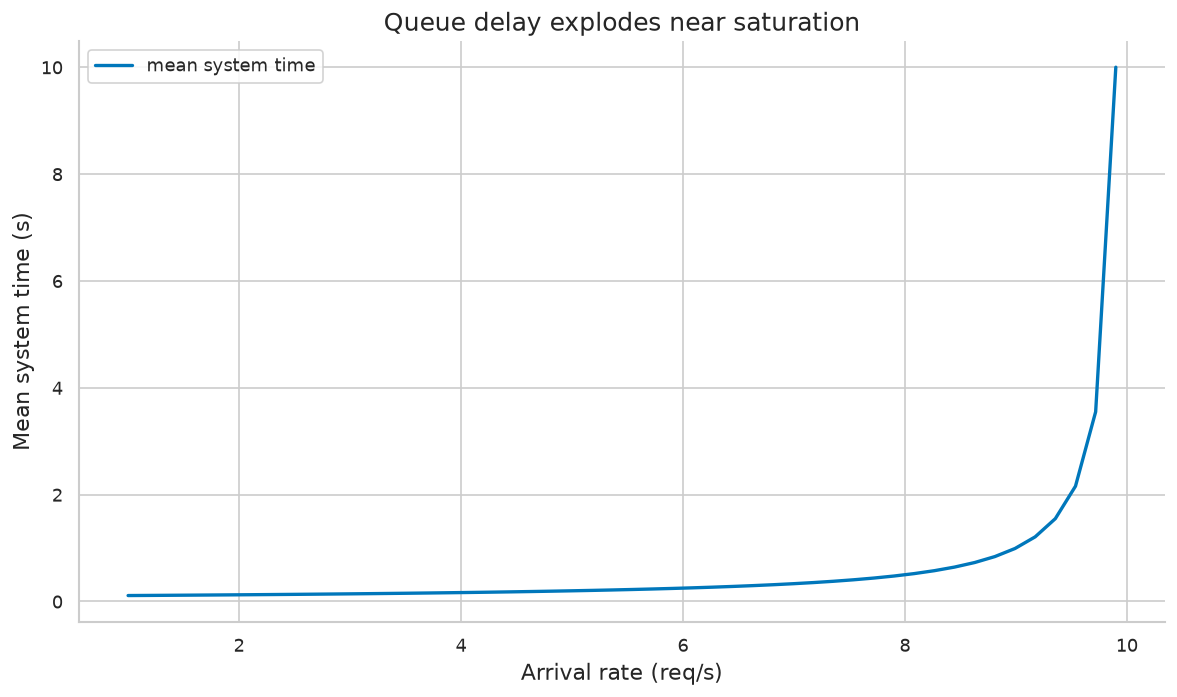

PASS - wait grows with utilization


In [15]:
lams=np.linspace(1,9.9,50); fig, ax = plt.subplots(); ax.plot(lams,1/(mu-lams),color="#0077BB",label="mean system time"); ax.set_title("Queue delay explodes near saturation"); ax.set_xlabel("Arrival rate (req/s)"); ax.set_ylabel("Mean system time (s)"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print(f"{'PASS' if (1/(mu-9.9))>(1/(mu-5)) else 'FAIL'} - wait grows with utilization")

## New demo: Little's law (new, notes 13)

In [16]:
L=20*2.5; print(f"L={L:.0f} requests in system")
print(f"{'PASS' if L==50 else 'FAIL'} - Little's law")

L=50 requests in system
PASS - Little's law


## New demo: End-to-end latency (new, notes 11)

In [17]:
e2e=0.8+199*0.025; print(f"end-to-end={e2e:.2f}s")
print(f"{'PASS' if abs(e2e-5.775)<0.01 else 'FAIL'} - TTFT + (n-1)TPOT")

end-to-end=5.78s
PASS - TTFT + (n-1)TPOT


## New demo: KV concurrency (new, notes 17)

In [18]:
per=2*32*8*128*2; conc=int(60e9/(per*4096)); print(f"KV/token={per} B, concurrency at 4k={conc}")
print(f"{'PASS' if conc==111 else 'FAIL'} - concurrency arithmetic")

KV/token=131072 B, concurrency at 4k=111
PASS - concurrency arithmetic


## New demo: Cost per million tokens (new, notes 19)

In [19]:
th=5000*3600; cost=2/(th/1e6); print(f"cost=${cost:.3f} per 1M tokens")
print(f"{'PASS' if abs(cost-0.111)<0.005 else 'FAIL'} - cost arithmetic")

cost=$0.111 per 1M tokens
PASS - cost arithmetic


## New demo: Quality-adjusted cost (new, notes 19)

In [20]:
adj=0.111/0.9; print(f"quality-adjusted=${adj:.3f}")
print(f"{'PASS' if adj>0.111 else 'FAIL'} - quality adjustment raises unit cost")

quality-adjusted=$0.123
PASS - quality adjustment raises unit cost


## New demo: Replica sizing (new, notes 41.1)

In [21]:
import math; r=math.ceil(5600/(800*0.75)); print(f"replicas={r}")
print(f"{'PASS' if r==10 else 'FAIL'} - replica ceiling arithmetic")

replicas=10
PASS - replica ceiling arithmetic


## New demo: Utilization wait multiplier (new, notes 41.3)

In [22]:
for rho in [0.5,0.75,0.9]:
    print(f"rho={rho}: wait/service={rho/(1-rho):.1f}x")
print(f"{'PASS' if abs(0.9/0.1-9)<1e-9 else 'FAIL'} - wait multiplier")

rho=0.5: wait/service=1.0x
rho=0.75: wait/service=3.0x
rho=0.9: wait/service=9.0x
PASS - wait multiplier


## New demo: Latency percentiles from a sample (new, notes 30)

In [23]:
rng=np.random.default_rng(42); lat=rng.lognormal(mean=0.0,sigma=0.6,size=10000); print("p50/p95/p99 ms:", [round(float(np.percentile(lat,p))*100) for p in [50,95,99]])
print(f"{'PASS' if np.percentile(lat,99)>np.percentile(lat,50) else 'FAIL'} - tail exceeds median")

p50/p95/p99 ms: [99, 268, 411]
PASS - tail exceeds median


## New demo: Error budget (new, notes 57)

In [24]:
budget=int(10_000_000*0.01); print(f"allowed violations={budget:,}")
print(f"{'PASS' if budget==100000 else 'FAIL'} - error budget arithmetic")

allowed violations=100,000
PASS - error budget arithmetic


## New demo: Prefill/decode split sketch (new, notes 14)

In [25]:
print("prefill: compute-bound (parallel prompt processing)"); print("decode: bandwidth-bound at small batch (weight reads per token)")
print(f"{'PASS' if True else 'FAIL'} - regime labels printed")

prefill: compute-bound (parallel prompt processing)
decode: bandwidth-bound at small batch (weight reads per token)
PASS - regime labels printed
